# MCM 처리 후 astrocyte ACHES와 SNAP-a 점수

**GSE282665**의 human iPSC-derived astrocyte를 비교한다. [다시 그리는 방법](README.md)

In [1]:
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

results_subdir = Path("data/perturbation_validation/results")
here = Path.cwd()
project = next(
    (path for path in (here, *here.parents) if (path / results_subdir / "program_scores.tsv").is_file()),
    None,
)
if project is None:
    raise FileNotFoundError("이 저장소의 루트 또는 notebooks/perturbation에서 실행하세요.")
results = project / results_subdir
figures = project / "figures"
dataset = "GSE282665"

planned = pd.read_csv(results / "planned_sample_scores.tsv", sep="\t")
coverage = pd.read_csv(results / "program_coverage.tsv", sep="\t")
planned = planned.loc[planned["dataset"].eq(dataset) & planned["recipient"].eq("astrocyte")]
coverage = coverage.loc[coverage["dataset"].eq(dataset) & coverage["recipient"].eq("astrocyte")]

## 표본 점수와 비교 괄호

점은 개별 표본, 가로선은 조건 평균, 회색 선은 같은 recipient line을 나타낸다. 같은 line 내 LPS-MCM과 resting-MCM을 양측 paired t-test로 비교했다. 그림의 q값은 ACHES와 SNAP-a 두 대비를 함께 BH 보정한 값이다. 표에는 대비별 평균 차이와 95% 신뢰구간을 함께 제공한다.

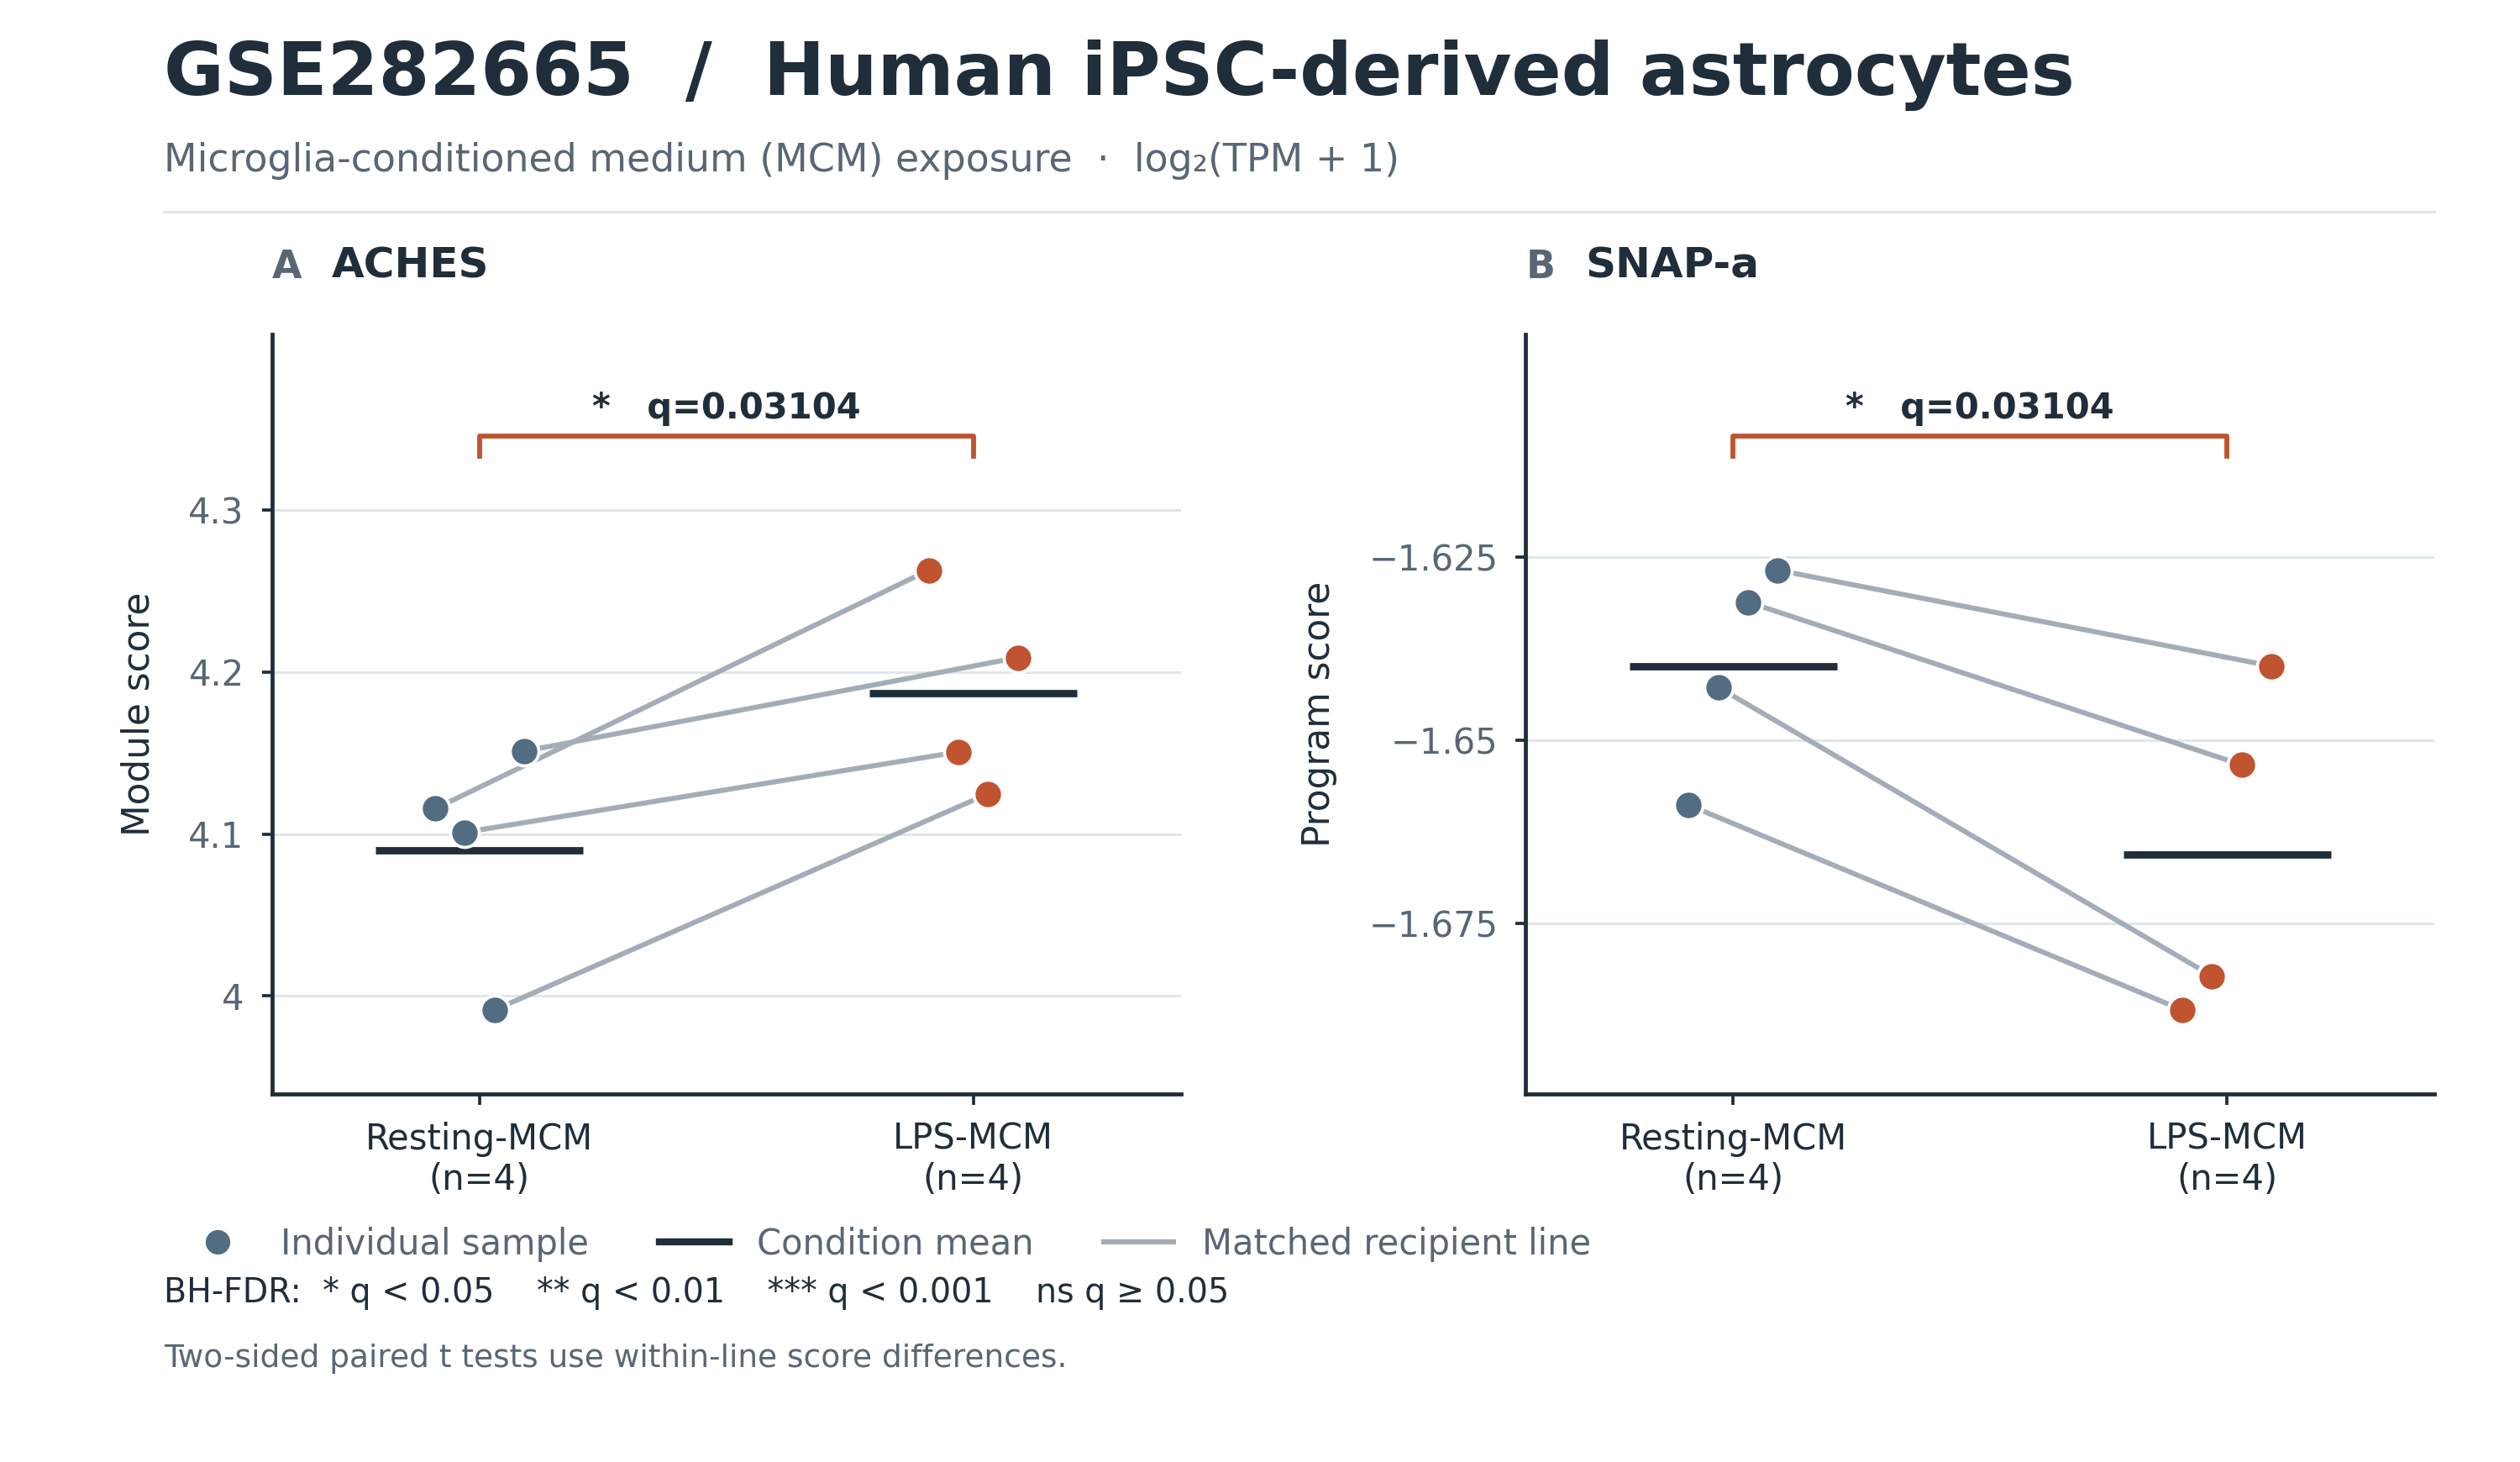

,dataset,recipient,program,treatment,method,n_reference,n_treatment,n_pairs,effect,ci_low,ci_high,p_value,q_value
0,GSE282665,astrocyte,ACHES,LPS-MCM,paired t,4,4,4,0.09702,0.01672,0.17732,0.03104,0.03104
1,GSE282665,astrocyte,SNAP-a,LPS-MCM,paired t,4,4,4,-0.02568,-0.04323,-0.00814,0.01866,0.03104


,dataset,recipient,program,scale,source_genes,retained_genes,gene_coverage,weight_mass_coverage,low_coverage
2,GSE282665,astrocyte,ACHES,log2(TPM+1),363,359,0.989,0.989,False
3,GSE282665,astrocyte,SNAP-a,log2(TPM+1),33611,25618,0.762,0.878,False


In [2]:
display(Image(filename=str(figures / "24.png"), width=900))

effects = pd.read_csv(results / "program_score_effects_ci.tsv", sep="\t")
effects = effects.loc[effects["dataset"].eq(dataset) & effects["recipient"].eq("astrocyte")]
effect_fields = ["dataset", "recipient", "program", "treatment", "method", "n_reference",
                 "n_treatment", "n_pairs", "effect", "ci_low", "ci_high", "p_value", "q_value"]
report = effects[effect_fields].copy()
for column in ("p_value", "q_value"):
    report[column] = report[column].map(lambda value: f"{value:.4g}")
display(report.round(5))
report_fields = ["dataset", "recipient", "program", "scale", "source_genes",
                 "retained_genes", "gene_coverage", "weight_mass_coverage", "low_coverage"]
display(coverage[report_fields].round(3))

## Astrocyte · ACHES와 SNAP-a

Healthy-control astrocyte에 healthy-control microglia MCM을 처리한 네 recipient line의 표본 점수다.

In [3]:
sample_fields = ["condition", "sample_id", "gsm_id", "ACHES", "SNAP-a"]
display(planned[sample_fields].reset_index(drop=True).round(6))

,condition,sample_id,gsm_id,ACHES,SNAP-a
0,LPS-MCM,ctrl1_ctrl_lps,GSM8669349,4.262867,-1.686818
1,LPS-MCM,ctrl2_ctrl_lps,GSM8669332,4.150663,-1.682190
2,LPS-MCM,ctrl4_ctrl_lps,GSM8669338,4.124825,-1.653338
3,LPS-MCM,ctrl6_ctrl_lps,GSM8669345,4.208856,-1.639849
4,Resting-MCM,ctrl1_ctrl_untx,GSM8669342,4.115617,-1.658843
5,Resting-MCM,ctrl2_ctrl_untx,GSM8669353,4.101048,-1.642758
6,Resting-MCM,ctrl4_ctrl_untx,GSM8669336,3.991370,-1.631112
7,Resting-MCM,ctrl6_ctrl_untx,GSM8669343,4.151096,-1.626751


[전체 표본 점수 TSV](../../data/perturbation_validation/results/planned_sample_scores.tsv) · [전체 대비 통계 TSV](../../data/perturbation_validation/results/program_score_effects_ci.tsv)

[그림 24 PDF](../../figures/24.pdf) · [SVG](../../figures/24.svg) · [전체 그림 색인](../../FIGURES.md)